In [1]:
import os
import matplotlib.pyplot as mp
import pandas as pd
import seaborn as sb
from sklearn.cluster import KMeans
# Cargar el conjunto de datos de clientes
dataset = pd.read_csv("iris.csv")

# Visualizar el DataFrame
dataset.head()

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [3]:
# Seleccionar todas las filas (:) y las columnas en las posiciones 2 y 3 del DataFrame,
# convirtiendo el resultado en un arreglo bidimensional de NumPy con .values
fields = dataset.iloc[:, [2, 3]].values

# Imprimir en pantalla el arreglo numérico generado
print(fields)

[[1.4 0.2]
 [1.4 0.2]
 [1.3 0.2]
 [1.5 0.2]
 [1.4 0.2]
 [1.7 0.4]
 [1.4 0.3]
 [1.5 0.2]
 [1.4 0.2]
 [1.5 0.1]
 [1.5 0.2]
 [1.6 0.2]
 [1.4 0.1]
 [1.1 0.1]
 [1.2 0.2]
 [1.5 0.4]
 [1.3 0.4]
 [1.4 0.3]
 [1.7 0.3]
 [1.5 0.3]
 [1.7 0.2]
 [1.5 0.4]
 [1.  0.2]
 [1.7 0.5]
 [1.9 0.2]
 [1.6 0.2]
 [1.6 0.4]
 [1.5 0.2]
 [1.4 0.2]
 [1.6 0.2]
 [1.6 0.2]
 [1.5 0.4]
 [1.5 0.1]
 [1.4 0.2]
 [1.5 0.2]
 [1.2 0.2]
 [1.3 0.2]
 [1.4 0.1]
 [1.3 0.2]
 [1.5 0.2]
 [1.3 0.3]
 [1.3 0.3]
 [1.3 0.2]
 [1.6 0.6]
 [1.9 0.4]
 [1.4 0.3]
 [1.6 0.2]
 [1.4 0.2]
 [1.5 0.2]
 [1.4 0.2]
 [4.7 1.4]
 [4.5 1.5]
 [4.9 1.5]
 [4.  1.3]
 [4.6 1.5]
 [4.5 1.3]
 [4.7 1.6]
 [3.3 1. ]
 [4.6 1.3]
 [3.9 1.4]
 [3.5 1. ]
 [4.2 1.5]
 [4.  1. ]
 [4.7 1.4]
 [3.6 1.3]
 [4.4 1.4]
 [4.5 1.5]
 [4.1 1. ]
 [4.5 1.5]
 [3.9 1.1]
 [4.8 1.8]
 [4.  1.3]
 [4.9 1.5]
 [4.7 1.2]
 [4.3 1.3]
 [4.4 1.4]
 [4.8 1.4]
 [5.  1.7]
 [4.5 1.5]
 [3.5 1. ]
 [3.8 1.1]
 [3.7 1. ]
 [3.9 1.2]
 [5.1 1.6]
 [4.5 1.5]
 [4.5 1.6]
 [4.7 1.5]
 [4.4 1.3]
 [4.1 1.3]
 [4.  1.3]
 [4.4 1.2]

In [5]:
import warnings  
warnings.filterwarnings("ignore")

In [7]:
wcss = []  # Crear lista vacía para almacenar la inercia (WCSS)

for index in range(1, 11):  # Probar de 1 a 10 clusters
  kmeans = KMeans(n_clusters=index, init="k-means++", random_state=2)  # Configurar modelo K-Means
  kmeans.fit(fields)  # Entrenar el modelo con los datos

  wcss.append(kmeans.inertia_)  # Guardar la inercia calculada

Text(0, 0.5, 'WCSS')

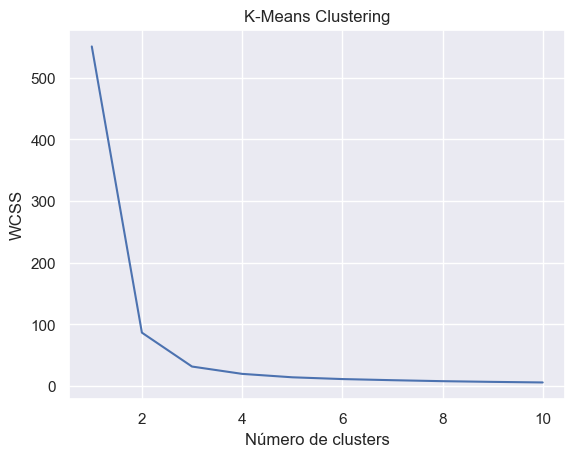

In [9]:
# Graficación del "Codo de Jambu"
sb.set()  # Aplicar estilo por defecto de seaborn
mp.plot(range(1, 11), wcss)  # Graficar WCSS contra número de clusters
mp.title("K-Means Clustering")  # Definir el título de la gráfica
mp.xlabel("Número de clusters")  # Etiquetar el eje horizontal X
mp.ylabel("WCSS")  # Weighted cluster sum of squares  # Etiquetar el eje vertical Y

In [11]:
kmeans = KMeans(n_clusters=3, init="k-means++", random_state=42)  # Configurar K-Means con 5 clusters
cluster_values = kmeans.fit_predict(fields)  # Entrenar modelo y asignar un cluster a cada dato
print(cluster_values)  # Imprimir la lista de clusters asignados

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 0 2 2 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 0 0 0 0 2 0 0 0 0
 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0
 0 0]


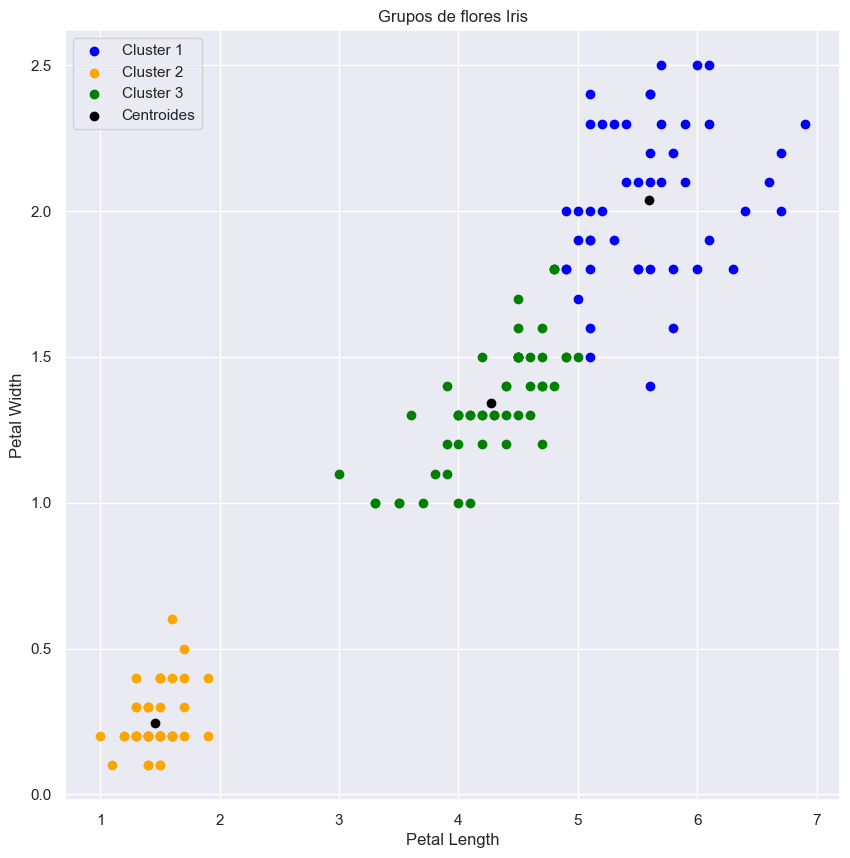

In [13]:
mp.figure(figsize=(10, 10))  # Definir tamaño del lienzo de la gráfica (10x10)
mp.scatter(fields[cluster_values == 0, 0], fields[cluster_values == 0, 1], c='blue', label='Cluster 1')  # Graficar los puntos del Cluster 1 
mp.scatter(fields[cluster_values == 1, 0], fields[cluster_values == 1, 1], c='orange', label='Cluster 2')  # Graficar los puntos del Cluster 2 
mp.scatter(fields[cluster_values == 2, 0], fields[cluster_values == 2, 1], c='green', label='Cluster 3')  # Graficar los puntos del Cluster 3 

mp.scatter(kmeans.cluster_centers_[:,0] , kmeans.cluster_centers_[:,1] , c='black', label= 'Centroides' )

mp.title("Grupos de flores Iris")
mp.xlabel("Petal Length")
mp.ylabel("Petal Width")
mp.legend()

In [15]:
# Criterio de Silueta ("Silhouette")
from sklearn import datasets 
from sklearn.metrics import silhouette_score 

In [17]:
X = dataset.iloc[:, [2, 3]].to_numpy()  # Convertir columnas 2 y 3 en arreglo NumPy

for j in range(2, 12):  # Probar de 2 a 11 clusters
  kmeans = KMeans(n_clusters=j, random_state=42)  # Configurar K-Means
  kmeans.fit_predict(X)  # Ajustar y predecir asignaciones de clusters
    
  # Calculamos el Score de Silueta
  score = silhouette_score(X, kmeans.labels_, metric='euclidean')  # Calcular el coeficiente de silueta
  print("Score Silhouette;", "k = ", j, ":", score)  # Imprimir resultado del score

Score Silhouette; k =  2 : 0.7653904101258123
Score Silhouette; k =  3 : 0.6604800083974887
Score Silhouette; k =  4 : 0.6127580794464402
Score Silhouette; k =  5 : 0.5883732712110276
Score Silhouette; k =  6 : 0.5767097832601947
Score Silhouette; k =  7 : 0.5640984340524553
Score Silhouette; k =  8 : 0.5902255624998716
Score Silhouette; k =  9 : 0.5783545667111449
Score Silhouette; k =  10 : 0.4212493802664013
Score Silhouette; k =  11 : 0.41947525990243273


In [19]:
# Algoritmo KMeans aplicado a las 4 variables numéricas
# bajo una transformación de PCA

fields2 = dataset.iloc[:, [0, 1, 2, 3]].values

print(fields2)  

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 3.1 4.

In [21]:
from sklearn import decomposition  # Importar módulo de reducción de dimensionalidad

pca = decomposition.PCA(n_components=2)  # Configurar PCA a 2 componentes
pca.fit(fields2)  # Ajustar el modelo con los datos
fields2 = pca.transform(fields2)  # Reducir los datos a 2 dimensiones
fields2  # Mostrar matriz resultante

array([[-2.68412563,  0.31939725],
       [-2.71414169, -0.17700123],
       [-2.88899057, -0.14494943],
       [-2.74534286, -0.31829898],
       [-2.72871654,  0.32675451],
       [-2.28085963,  0.74133045],
       [-2.82053775, -0.08946138],
       [-2.62614497,  0.16338496],
       [-2.88638273, -0.57831175],
       [-2.6727558 , -0.11377425],
       [-2.50694709,  0.6450689 ],
       [-2.61275523,  0.01472994],
       [-2.78610927, -0.235112  ],
       [-3.22380374, -0.51139459],
       [-2.64475039,  1.17876464],
       [-2.38603903,  1.33806233],
       [-2.62352788,  0.81067951],
       [-2.64829671,  0.31184914],
       [-2.19982032,  0.87283904],
       [-2.5879864 ,  0.51356031],
       [-2.31025622,  0.39134594],
       [-2.54370523,  0.43299606],
       [-3.21593942,  0.13346807],
       [-2.30273318,  0.09870885],
       [-2.35575405, -0.03728186],
       [-2.50666891, -0.14601688],
       [-2.46882007,  0.13095149],
       [-2.56231991,  0.36771886],
       [-2.63953472,

In [23]:
wcss2 = []  # Crear lista vacía para almacenar inercia

for index in range(1, 11):  # Probar de 1 a 10 clusters
    kmeans = KMeans(n_clusters = index, init = "k-means++", random_state = 2)  # Configurar K-Means
    kmeans.fit(fields2)  # Entrenar modelo con datos transformados
    
    wcss2.append(kmeans.inertia_)  # Guardar inercia calculada

Text(0, 0.5, 'WCSS')

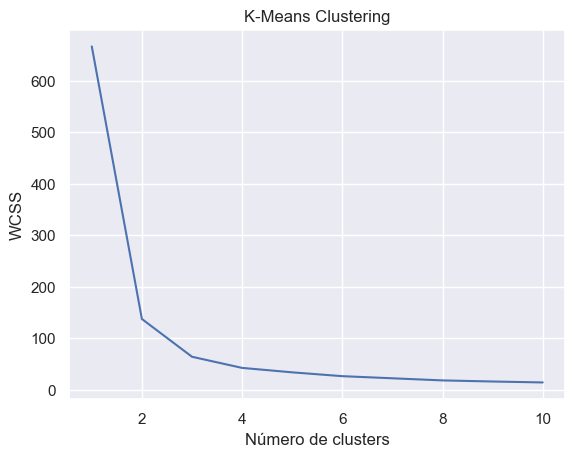

In [25]:
# Graficación del "Codo de Jambu"
sb.set()  # Estilo de seaborn
mp.plot(range(1, 11), wcss2)  # Graficar WCSS2 contra número de clusters
mp.title("K-Means Clustering")  # Título de la gráfica
mp.xlabel("Número de clusters")  # Etiqueta eje X
mp.ylabel("WCSS")  # Weighted cluster sum of squares  # Etiqueta eje Y

In [27]:
kmeans = KMeans(n_clusters = 3, init = "k-means++", random_state = 42)  # Configurar modelo KMeans
cluster_values = kmeans.fit_predict(fields2)  # Asignar clusters a los datos transformados
print(cluster_values)  # Imprimir asignación de clusters

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 0 0 0 2 0 0 0 0
 0 0 2 2 0 0 0 0 2 0 2 0 2 0 0 2 2 0 0 0 0 0 2 0 0 0 0 2 0 0 0 2 0 0 0 2 0
 0 2]


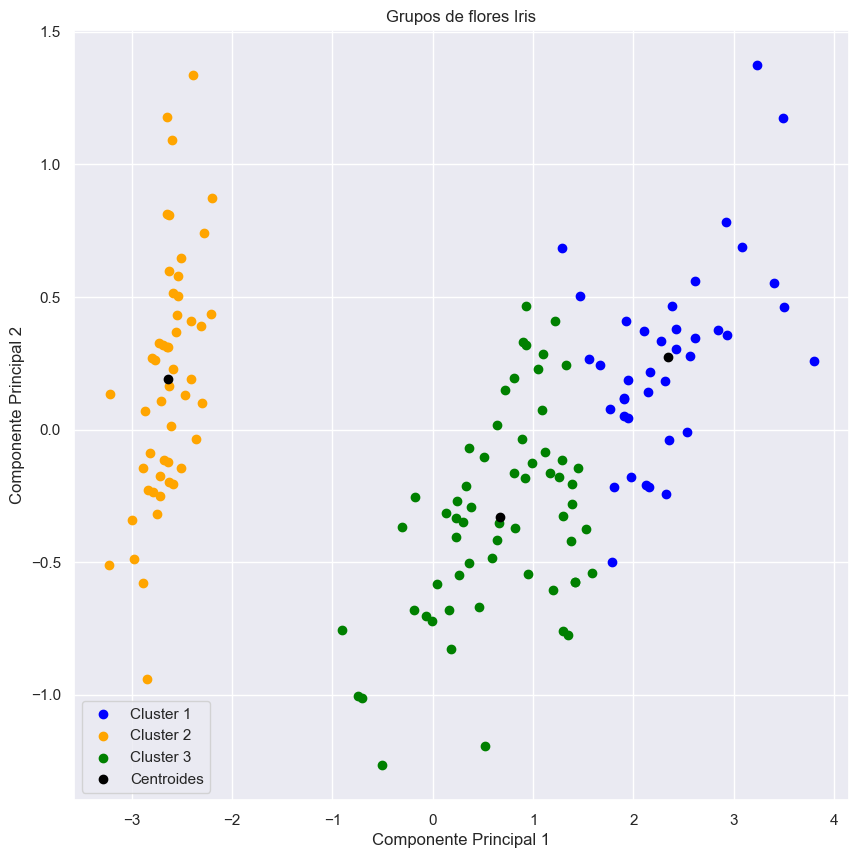

In [29]:
mp.figure(figsize =(10,10))  # Definir tamaño de la figura

mp.scatter(fields2[cluster_values==0,0], fields2[cluster_values==0,1], c = 'blue', label = 'Cluster 1')  # Graficar Cluster 1
mp.scatter(fields2[cluster_values==1,0], fields2[cluster_values==1,1], c = 'orange', label = 'Cluster 2')  # Graficar Cluster 2
mp.scatter(fields2[cluster_values==2,0], fields2[cluster_values==2,1], c = 'green', label = 'Cluster 3')  # Graficar Cluster 3

mp.scatter(kmeans.cluster_centers_[:,0],kmeans.cluster_centers_[:,1], c = 'black', label = 'Centroides')  # Graficar centroides de cada cluster

mp.title("Grupos de flores Iris")
mp.xlabel("Componente Principal 1")
mp.ylabel("Componente Principal 2")
mp.legend()

4. ¿Obtuvo los mismos 
resultados de agrupamiento? Comente sobre la ventaja práctica de habe 
efectuado la transformación por PCA antes de aplicar el algoritmo K-Medi?s.

Comparación: Los resultados de agrupamiento obtenidos antes y después de aplicar PCA son similares, ya que en ambos casos se identifican tres grupos principales de flores. Al aplicar PCA, cambia la representación gráfica de los datos, debido a que las variables originales son transformadas en dos componentes principales; sin embargo, la estructura general de los grupos se mantiene.

Ventaja práctica del PCA: La aplicación de PCA antes de K-Medias permite reducir la dimensionalidad de los datos, pasando de cuatro variables originales a dos componentes principales, facilitando la visualización y reduciendo la complejidad del análisis, mientras se conserva la mayor cantidad posible de información de los datos.